# Layer-25 causal replay: Control 1, Exp 2 readiness and progress (#220)

Design: **Baseline** (no SAE) · **Exp 1** custom SAE and **Exp 2** pretrained SAE, each with targeted ablations of the probe-selected features, **Control 1** (the SAE with no ablation) and **Control 2** (random ablations).
Exp 1 (TopK) is in `causal_topk_layer25_results.ipynb`. This notebook adds Control 1 for every SAE, the edit-size check run before Exp 2, and where each condition stands. Every number is read from committed files.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUNB = ROOT / "results/causal_reconstruction_control_layer25/20261103T202307480433Z"
TOPK = ROOT / "results/causal_topk_mixed_layer25/20261103T024624099539Z/distributed/merged_exclude_empty6"
AUDIT = ROOT / "results/causal_pretrained_layer25/edit_norm_audit.json"
OUT = ROOT / "reports/figures/causal_layer25_controls"
(OUT / "tables").mkdir(parents=True, exist_ok=True)

INPUTS = [RUNB / n for n in ("reconstruction_damage.csv", "replay_config.json", "replay_check.json",
                             "claude_labeled/summary.json", "episodes.csv")]
INPUTS += [TOPK / n for n in ("targeted_vs_random.csv", "diagnostics.csv", "claude_labeled/summary.json")] + [AUDIT]
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
BEFORE = {str(p.relative_to(ROOT)): sha(p) for p in INPUTS}

damage = pd.read_csv(RUNB / "reconstruction_damage.csv")
runb_cfg = json.loads((RUNB / "replay_config.json").read_text())["config"]
runb_check = json.loads((RUNB / "replay_check.json").read_text())
runb_labels = json.loads((RUNB / "claude_labeled/summary.json").read_text())
runb_episodes = pd.read_csv(RUNB / "episodes.csv")
tvr = pd.read_csv(TOPK / "targeted_vs_random.csv")
topk_diag = pd.read_csv(TOPK / "diagnostics.csv")
topk_labels = json.loads((TOPK / "claude_labeled/summary.json").read_text())
audit = json.loads(AUDIT.read_text())

SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SAE_COLOR = {"TopK SAE": "#2a78d6", "Pretrained SAE": "#eb6834", "Adapted pretrained SAE": "#1baf7a"}
NAMES = {"TopK SAE": "TopK (custom)", "Pretrained SAE": "Pretrained (original Gemma Scope)",
         "Adapted pretrained SAE": "Pretrained, decoder fine-tuned"}
plt.rcParams.update({"font.family": ["Arial", "DejaVu Sans"], "font.size": 11, "svg.fonttype": "none",
                     "svg.hashsalt": "issue220", "figure.facecolor": SURF, "axes.facecolor": SURF,
                     "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
                     "xtick.color": MUTED, "xtick.labelcolor": MUTED, "ytick.color": INK2, "ytick.labelcolor": INK,
                     "figure.dpi": 110})


def one(df, **where):
    """The single row matching every column=value; anything else is an error, never a silent pick."""
    hit = df
    for col, val in where.items():
        hit = hit[hit[col] == val]
    if len(hit) != 1:
        raise ValueError(f"expected one row for {where}, got {len(hit)}")
    return hit.iloc[0]


def ci(text):
    return tuple(float(v) for v in str(text).strip("[]").split(","))


def show(df, name):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=False)
    display(df.style.hide(axis="index"))


def save(fig, name):
    fig.savefig(OUT / f"{name}.svg", bbox_inches="tight", pad_inches=0.25, metadata={"Date": None})
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight", pad_inches=0.25, metadata={"CreationDate": None})
    plt.show()


assert runb_cfg["reconstruction"] and not runb_cfg["error_preserving"], "Run B must be the reconstruction splice"
assert runb_check["passed"] and runb_labels["status"] in ("complete", "complete_with_exclusions")
assert set(damage.Experiment) == set(NAMES)
n_b = int(damage.N.iloc[0])
assert (damage.N == n_b).all() and n_b == len(runb_episodes) - len(runb_labels["excluded_questions"])
print(f"Run B: {n_b} analysed episodes (first {runb_cfg['limit']} of the seed-42 order requested; "
      f"{len(runb_labels['excluded_questions'])} excluded) · inputs hashed")

Run B: 249 analysed episodes (first 250 of the seed-42 order requested; 1 excluded) · inputs hashed


## 1 · Control 1: does the SAE alone change the Solver?

SAE,Reconstruction error (% of ‖x‖),Answers changed (%),Labels changed (%),"Adoption, plain (%)","Adoption, SAE only (%)",Δ adoption (pp),95% CI,p
TopK (custom),4.200000,1.200000,0.800000,48.600000,49.400000,0.800000,"[0.00, 2.01]",0.497000
Pretrained (original Gemma Scope),13.000000,3.200000,3.200000,48.600000,48.600000,0.000000,"[-2.01, 2.41]",1.000000
"Pretrained, decoder fine-tuned",7.800000,2.800000,1.200000,48.600000,48.200000,-0.400000,"[-2.01, 0.80]",1.000000


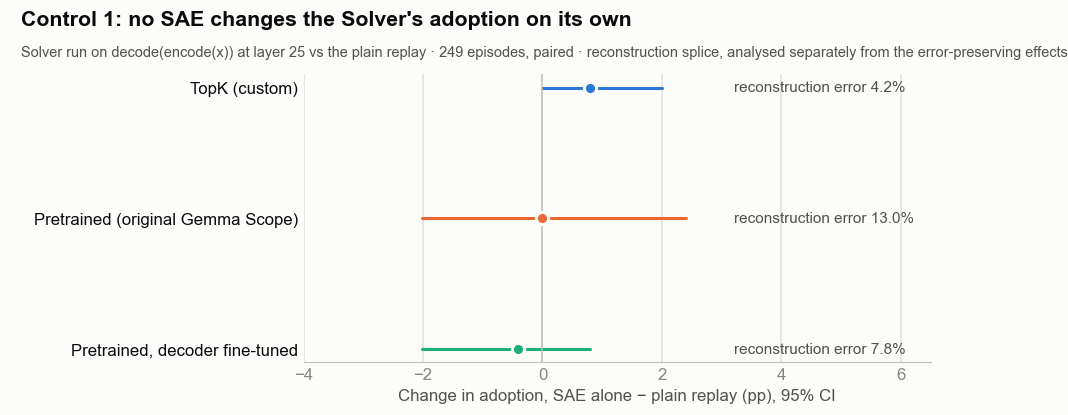

In [2]:
c1 = pd.DataFrame([{
    "SAE": NAMES[e], "Reconstruction error (% of ‖x‖)": round(100 * r["Mean reconstruction error (rel. to |x|)"], 1),
    "Answers changed (%)": round(r["Answer changed vs. control (%)"], 1), "Labels changed (%)": round(r["Label changed vs. control (%)"], 1),
    "Adoption, plain (%)": round(r["Plain replay acceptance (%)"], 1), "Adoption, SAE only (%)": round(r["Reconstruction-only acceptance (%)"], 1),
    "Δ adoption (pp)": round(r["Δ (pp)"], 2), "95% CI": r["95% CI for Δ"], "p": round(r["p-value"], 3)}
    for e in NAMES for r in [one(damage, Experiment=e)]])
show(c1, "1_control1")

fig, ax = plt.subplots(figsize=(9.5, 3.4))
fig.subplots_adjust(left=0.3)
for i, e in enumerate(NAMES):
    r = one(damage, Experiment=e)
    lo, hi = ci(r["95% CI for Δ"])
    ax.plot([lo, hi], [i, i], color=SAE_COLOR[e], linewidth=2, solid_capstyle="round", zorder=2)
    ax.scatter([r["Δ (pp)"]], [i], s=64, color=SAE_COLOR[e], edgecolors=SURF, linewidths=2, zorder=3)
    ax.text(3.2, i, f"reconstruction error {100 * r['Mean reconstruction error (rel. to |x|)']:.1f}%", va="center",
            fontsize=10, color=INK2)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(range(len(NAMES)), list(NAMES.values()))
ax.invert_yaxis()
ax.set_xlim(-4, 6.5)
ax.set_xlabel("Change in adoption, SAE alone − plain replay (pp), 95% CI")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.grid(axis="x", color=GRID, linewidth=1)
ax.set_axisbelow(True)
where = ("figure fraction", "axes fraction")
ax.annotate("Control 1: no SAE changes the Solver's adoption on its own", (0.02, 1), xycoords=where, xytext=(0, 32),
            textcoords="offset points", fontsize=14, fontweight="bold", color=INK)
ax.annotate(f"Solver run on decode(encode(x)) at layer 25 vs the plain replay · {n_b} episodes, paired · "
            "reconstruction splice, analysed separately from the error-preserving effects", (0.02, 1), xycoords=where,
            xytext=(0, 12), textcoords="offset points", fontsize=9.5, color=INK2)
save(fig, "1_control1")

## 2 · Exp 2 readiness: are the targeted and random edits the same size?

In [3]:
topk_a = audit["TopK (calibration, causal_topk_mixed_layer25.yaml)"]
runa_a = audit["Run A (causal_pretrained_layer25.yaml)"]
measured = {"TopK SAE · all 10": "TopK SAE · error-preserving", "TopK SAE · f1666": "TopK SAE · f1666 · error-preserving",
            "TopK SAE · without_1666": "TopK SAE · without_1666 · error-preserving"}
rows = []
for key, r in [*topk_a.items(), *runa_a.items()]:
    m = measured.get(key)
    size = lambda side: 100 * float(one(topk_diag, Experiment=m, Condition=f"{side} ablation")["Mean edit norm (rel. to |x|)"])
    rows.append({"SAE · features turned off": key.replace("without_1666", "other 9").replace("Adapted pretrained SAE", "Pretrained, fine-tuned"),
                 "Targeted edit (% of ‖x‖)": round(100 * r["targeted_mean"], 2), "Random edit (% of ‖x‖)": round(100 * r["random_mean"], 2),
                 "Targeted ÷ random": round(r["ratio_of_means"], 2),
                 "2% dose capped: targeted / random (%)": f"{r['capped_at_2%_pct']['targeted']:.0f} / {r['capped_at_2%_pct']['random']:.0f}",
                 "Measured in the TopK run (%)": "—" if m is None else f"{size('Targeted'):.2f} / {size('Random'):.2f}"})
show(pd.DataFrame(rows), "2_edit_sizes")
p, f = runa_a["Pretrained SAE · all 10"], runa_a["Adapted pretrained SAE · all 10"]
print(f"Full ablation, the replay's own {p['n_draws']} draws, {p['n_rows']:,} validation activations: for both pretrained SAEs "
      f"the random edit is {1 / p['ratio_of_means']:.1f}× / {1 / f['ratio_of_means']:.1f}× the targeted one (the reverse of TopK's "
      f"{topk_a['TopK SAE · all 10']['ratio_of_means']:.0f}×). A null targeted − random result for them would be ambiguous; a negative one conservative.")

SAE · features turned off,Targeted edit (% of ‖x‖),Random edit (% of ‖x‖),Targeted ÷ random,2% dose capped: targeted / random (%),Measured in the TopK run (%)
TopK SAE · all 10,86.080000,3.340000,25.810000,0 / 18,86.07 / 3.31
TopK SAE · f1666,85.430000,1.280000,66.900000,0 / 73,85.37 / 1.28
TopK SAE · other 9,2.320000,2.800000,0.830000,38 / 32,2.68 / 2.79
Pretrained SAE · all 10,2.200000,9.090000,0.240000,36 / 2,—
"Pretrained, fine-tuned · all 10",2.190000,9.050000,0.240000,38 / 2,—


Full ablation, the replay's own 100 draws, 1,000 validation activations: for both pretrained SAEs the random edit is 4.1× / 4.1× the targeted one (the reverse of TopK's 26×). A null targeted − random result for them would be ambiguous; a negative one conservative.


## 3 · Experimental design vs progress

In [4]:
t = one(tvr, Experiment="TopK SAE · error-preserving", Arm="ablation", Control="matched features", Rows="all")
f1 = one(tvr, Experiment="TopK SAE · f1666 · error-preserving", Arm="ablation", Control="matched features", Rows="all")
fmt = lambda e: (lambda r: f"{r['Δ (pp)']:+.1f} pp {r['95% CI for Δ']}")(one(damage, Experiment=e))
status = pd.DataFrame([
    ("Baseline: no SAE", "Done", "plain replay = stored answers in every run (TopK 500/500)"),
    ("Exp 1 · custom TopK SAE · targeted", "Done",
     f"{topk_labels['n_analysis_episodes']} episodes · all 10: {t['Targeted − random (pp)']:+.1f} pp vs random "
     f"(Holm p {t['p-value (Holm)']:.4f}) · f1666 alone {f1['Targeted − random (pp)']:+.1f} pp"),
    ("Exp 1 · Control 2 · random ablations", "Done", "100 contribution-matched draws per arm"),
    ("Exp 1 · Control 1 · no ablation", "Done", f"{n_b} episodes · {fmt('TopK SAE')}"),
    ("Exp 2 · original pretrained SAE · targeted + random", "Running", "Run A: 250 episodes, 100 draws; pilots passed"),
    ("Exp 2 · Control 1 · no ablation", "Done", f"{n_b} episodes · {fmt('Pretrained SAE')}"),
    ("Variant · fine-tuned pretrained · targeted + random", "Running", "in Run A, beside the original"),
    ("Variant · Control 1 · no ablation", "Done", f"{n_b} episodes · {fmt('Adapted pretrained SAE')}"),
    ("L1 SAE, Raw activations", "Pending", "same episodes, after Run A"),
    ("Part 2 · LLM interpreting dense activations", "Pending", "after the causal comparisons"),
], columns=["Condition", "Status", "Evidence"])
show(status, "3_status")
print("Run A status is as of 2026-11-03 evening (it runs outside this repository); every other row is read from committed results.")

AFTER = {str(p.relative_to(ROOT)): sha(p) for p in INPUTS}
assert AFTER == BEFORE, "inputs changed while the notebook ran"
(OUT / "tables" / "inputs_sha256.json").write_text(json.dumps(BEFORE, indent=2) + "\n")

Condition,Status,Evidence
Baseline: no SAE,Done,plain replay = stored answers in every run (TopK 500/500)
Exp 1 · custom TopK SAE · targeted,Done,494 episodes · all 10: -5.1 pp vs random (Holm p 0.0006) · f1666 alone -3.6 pp
Exp 1 · Control 2 · random ablations,Done,100 contribution-matched draws per arm
Exp 1 · Control 1 · no ablation,Done,"249 episodes · +0.8 pp [0.00, 2.01]"
Exp 2 · original pretrained SAE · targeted + random,Running,"Run A: 250 episodes, 100 draws; pilots passed"
Exp 2 · Control 1 · no ablation,Done,"249 episodes · +0.0 pp [-2.01, 2.41]"
Variant · fine-tuned pretrained · targeted + random,Running,"in Run A, beside the original"
Variant · Control 1 · no ablation,Done,"249 episodes · -0.4 pp [-2.01, 0.80]"
"L1 SAE, Raw activations",Pending,"same episodes, after Run A"
Part 2 · LLM interpreting dense activations,Pending,after the causal comparisons


Run A status is as of 2026-11-03 evening (it runs outside this repository); every other row is read from committed results.


1504